# Практика №3

Теперь в качестве акустической модели мы будем использовать простой DNN классификатор. На каждом кадре записи мы будем подавать его вектор признаков на DNN, которая будет выдавать "распределение вероятностей" по фонемам. Далее это распределение мы будем использовать в нашем алгоритме распознавания по словарю. Схема работы такого классификатора представлена ниже: 

![](https://drive.google.com/uc?export=view&id=1dv0VuE8DIoKXETbvnZq2PMixkWMCJOxr)

### Bootstrap

In [ ]:
!gdown --id '1meikF0XqBUnVZKoY3160MQ0R25lq-EMu'
!gdown --id '1f0LkW6I3Q5CnOThuNFAJ9umgnb2eU4Ox'

!unzip -q lab2.zip
!unzip -q train_librispeech_10h.zip
!mv lab2 lab3
!mv train_librispeech_10h lab3/data
!rm -rf lab2.zip sample_data train_librispeech_10h.zip
%cd lab3

Downloading...
From: https://drive.google.com/uc?id=1meikF0XqBUnVZKoY3160MQ0R25lq-EMu
To: /content/lab2.zip
100% 1.66M/1.66M [00:00<00:00, 113MB/s]
Downloading...
From: https://drive.google.com/uc?id=1f0LkW6I3Q5CnOThuNFAJ9umgnb2eU4Ox
To: /content/train_librispeech_10h.zip
679MB [00:05, 121MB/s]
/content/lab3


In [ ]:
import os
import numpy as np
import time
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import IPython.display as ipd
import librosa, librosa.display
import torch
import torch.nn as nn
import torch.functional as F

In [ ]:
#@markdown Plotting style (default is styled like plots from [FiveThirtyeight.com](https://fivethirtyeight.com/))
matplotlib_style = 'fivethirtyeight' #@param ['fivethirtyeight', 'bmh', 'ggplot', 'seaborn', 'default', 'Solarize_Light2', 'classic', 'dark_background', 'seaborn-colorblind', 'seaborn-notebook']
import matplotlib.pyplot as plt
plt.style.use(matplotlib_style)
%matplotlib inline
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'
 
#@markdown Resolution of the plot outputs (`retina` is the highest resolution)
notebook_screen_res = 'retina' #@param ['retina', 'png', 'jpeg', 'svg', 'pdf']
%config InlineBackend.figure_format = notebook_screen_res

In [ ]:
# загрузка списка допустимых фонем:
def load_phones_dict(phones_file):
    phones_dict = {}
    with open(phones_file, encoding='utf-8') as fn:
        for index, line in enumerate(fn):
            phones_dict[line.strip()] = index
    return phones_dict

# загрузка покадровой фонемной разметки в словарь:
def load_phone_aligment(aligment_file):
    ali_dict = {}
    with open(aligment_file, encoding='utf-8') as fn:
        for line in fn:
            line = line.strip().split()
            ali_dict[line[0]] = line[1:]
    return ali_dict

# подсчет акустических признаков для записей из папки:
def load_data_dict(dir_path, count=None):
    data_dict = {}
    step = 0
    for wav_name in tqdm(os.listdir(dir_path)):
        x, sr = librosa.load(os.path.join(dir_path, wav_name), sr=None) 
        mfcc = librosa.feature.mfcc(x, sr=sr, n_mfcc=13, 
                                    n_fft=int(sr * 0.025),
                                    hop_length=int(sr * 0.01))
        step += 1
        if count and step == count:
            print(f'Early stop at {step}th file..')
            break
        data_dict[wav_name.split('.')[0]] = mfcc.T  
    return data_dict


phones_file = 'data/train_librispeech_10h/phones'
phones_dict = load_phones_dict(phones_file)

ali_file = 'data/train_librispeech_10h/ali_phones.txt'
ali_dict = load_phone_aligment(ali_file)

train_records_dir = 'data/train_librispeech_10h/wav_dir'
feats_dict = load_data_dict(train_records_dir, count=1000)

Early stop at 1000th file..


### Априорная вероятность:

![](https://drive.google.com/uc?export=view&id=1WhjclhXm2POYsCgvxp3iAIOvT9F_k8If)

In [ ]:
# объединение кадров признаков с соответствующими им фонемам:
def combain_data(ali_dict, feats_dict, phones_dict, side_context=None):
    data_list = []
    priors_list = [0] * len(phones_dict) # P(q_t)
    for file_name in feats_dict.keys():
        file_feats = feats_dict[file_name]
        file_ali = ali_dict[file_name]
        for frame in range(min(len(file_feats), len(file_ali))):
            data_list.append(np.append(file_feats[frame], phones_dict[file_ali[frame]]))
            priors_list[phones_dict[file_ali[frame]]] += 1
    return data_list, np.array(priors_list)/sum(priors_list)

side_context = None
data_list, priors_list = combain_data(ali_dict, feats_dict, phones_dict, side_context)
data_list = np.random.permutation(data_list)

In [ ]:
class CommonDataSet():

    def __init__(self, data_list, device, valid_proportion=0.1):
        self.train = data_list[:int((1-valid_proportion)*len(data_list))]
        self.valid = data_list[int((1-valid_proportion)*len(data_list)):]
        self.device = device
        
    def num_batches(self, batch_size):
        return len(self.train)//batch_size        
        
    def next_batch(self, batch_size):
        for i in range(self.num_batches(batch_size)):
            batch_xs = torch.tensor(self.train[i * batch_size:(i + 1) * batch_size, :-1], dtype=torch.float32)
            batch_ys = torch.tensor(self.train[i * batch_size:(i + 1) * batch_size,-1].ravel(), dtype=torch.int64)

            yield batch_xs.to(device), batch_ys.to(device)

In [ ]:
class MyNet(torch.nn.Module):

    def __init__(self, input_dim, output_dim):
        super(MyNet, self).__init__()
        # params:
        input_dim = input_dim       # размерность входных признаков
        n_nodes_hl1 = 256
        n_nodes_hl2 = 256
        n_nodes_hl3 = 256
        n_nodes_hl4 = 256
        output_dim = output_dim     # количество выходных классов (фонем)
        # FC layers:
        self.fc1 = nn.Linear(input_dim, n_nodes_hl1)
        self.fc2 = nn.Linear(n_nodes_hl1, n_nodes_hl2)
        self.fc3 = nn.Linear(n_nodes_hl2, n_nodes_hl3)
        self.fc4 = nn.Linear(n_nodes_hl3, n_nodes_hl4)
        self.fc5 = nn.Linear(n_nodes_hl4, output_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = torch.relu(self.fc4(x))
        x = self.fc5(x)
        return (x)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# load data:
data_set = CommonDataSet(data_list, device)

batch_size = 256   # optimal ?????

# training network model:
start = time.time() 
net = MyNet(input_dim=(data_list[0].shape[0] - 1),
            output_dim=len(phones_dict.keys())).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.0001)

loss_list = []

print('TRAINING IS STARTED...')
for epoch in range(10):
    running_loss = 0
    counter = 0
    for batch_xs, batch_ys in tqdm(data_set.next_batch(batch_size), \
                                   total=data_set.num_batches(batch_size), \
                                   desc='epoch {}'.format(epoch)):
        optimizer.zero_grad()
        output = net(batch_xs)

        loss = criterion(output, batch_ys)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        counter += 1
        
    print('loss is: {:.4f}'.format((running_loss / counter)))
    loss_list.append(running_loss / counter)
    
end = time.time()
minutes = (end - start) // 60
seconds = np.mod((end - start), 60)
print('Time is: {} min {} sec'.format(int(minutes), int(seconds)))

TRAINING IS STARTED...



loss is: 2.2883



loss is: 2.1729



loss is: 2.1366



loss is: 2.1134



loss is: 2.0955



loss is: 2.0803



loss is: 2.0669



loss is: 2.0549



loss is: 2.0438



loss is: 2.0337
Time is: 2 min 23 sec


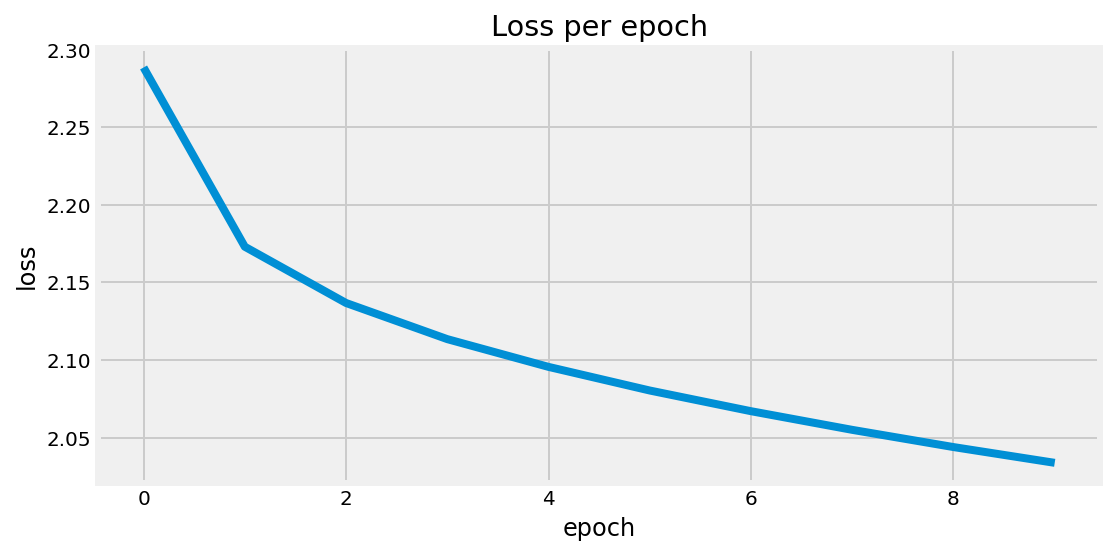

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_list)
plt.title('Loss per epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.grid(True)
plt.show()

In [ ]:
net.cpu()
with torch.no_grad():
    correct_cnt = 0
    for ftr, true_label in tqdm(zip(data_set.valid[:, :-1], data_set.valid[:, -1]), total=data_set.valid.shape[0]):
        ftr = torch.from_numpy(ftr).float()
        output = net.forward(ftr)
        correct_cnt += (output.argmax().item() == true_label)
        
    print("Total frame accuracy is {:.3f}".format(correct_cnt / data_set.valid.shape[0]))


Total frame accuracy is 0.423


In [ ]:
class_correct = [0 for x in range(len(phones_dict.keys()))]
class_total = [0 for x in range(len(phones_dict.keys()))]
net.cpu()
with torch.no_grad():
    for ftr, true_label in tqdm(zip(data_set.valid[:, :-1], data_set.valid[:, -1]), total=data_set.valid.shape[0]):
        ftr = torch.from_numpy(ftr).float()
        output = net.forward(ftr)
        predict_label = output.argmax().item()
        
        class_correct[predict_label] += (predict_label == int(true_label))
        class_total[int(true_label)] += 1

for idx, phone in enumerate(phones_dict.keys()):
    if class_total[idx]:
        print('{:3s}: {:.2f} : {}/{}'.format(phone, class_correct[idx] / class_total[idx], \
                                                     class_correct[idx], class_total[idx]))


SIL: 0.95 : 20763/21813
SPN: 0.00 : 0/601
AA0: 0.00 : 0/45
AA1: 0.28 : 521/1841
AA2: 0.00 : 0/81
AE0: 0.00 : 0/48
AE1: 0.40 : 1390/3461
AE2: 0.00 : 0/104
AH0: 0.31 : 1774/5754
AH1: 0.28 : 534/1924
AH2: 0.00 : 0/54
AO0: 0.00 : 0/20
AO1: 0.36 : 702/1974
AO2: 0.00 : 0/45
AW0: 0.00 : 0/5
AW1: 0.06 : 71/1124
AW2: 0.00 : 0/28
AY0: 0.00 : 0/54
AY1: 0.25 : 695/2798
AY2: 0.00 : 0/180
B  : 0.10 : 153/1540
CH : 0.03 : 29/929
D  : 0.15 : 624/4088
DH : 0.04 : 76/2033
EH0: 0.00 : 0/49
EH1: 0.28 : 782/2830
EH2: 0.00 : 0/90
ER0: 0.33 : 890/2658
ER1: 0.19 : 194/1029
ER2: 0.00 : 0/20
EY0: 0.00 : 0/19
EY1: 0.45 : 1114/2490
EY2: 0.00 : 0/170
F  : 0.46 : 1036/2231
G  : 0.00 : 3/759
HH : 0.20 : 418/2115
IH0: 0.09 : 224/2589
IH1: 0.16 : 378/2393
IH2: 0.00 : 0/82
IY0: 0.29 : 594/2083
IY1: 0.53 : 1181/2239
IY2: 0.00 : 0/70
JH : 0.05 : 34/680
K  : 0.28 : 815/2961
L  : 0.56 : 2340/4154
M  : 0.33 : 1048/3205
N  : 0.50 : 3080/6146
NG : 0.16 : 206/1261
OW0: 0.00 : 0/205
OW1: 0.18 : 347/1903
OW2: 0.00 : 0/124
OY1: 

### Распознавание по словарю с помощью нейронки

In [ ]:
# теперь будем распознавать по словарю, состоящему из конечных слов
# для этого нужно загрузить файл лексикона, который определяет из каких фонем состоят наши слова
def load_lexicon_dict(lexicon_file):
    lexicon_dict = {}
    with open(lexicon_file, encoding='utf-8') as fn:
        for line in fn:
            line = line.strip().split()
            lexicon_dict[line[0]] = line[1:]
    return lexicon_dict

In [ ]:
class AcousticModel:
    def __init__(self, phone_name, phone_index, priors_list):
        self.phone_name = phone_name
        self.phone_index = phone_index
        self.phone_prior = priors_list[phone_index]
        
    def distance(self, input_feats, nnet):
        with torch.no_grad():
            predicts = nnet.forward(torch.tensor(input_feats, dtype=torch.float32))
            softmax = torch.nn.functional.softmax(predicts, dim=0)
        return -np.log(softmax[self.phone_index].item() / self.phone_prior)

class State:
    def __init__(self, model, index):  
        self.model = model                     # вектор признаков узла
        self.is_final = False                  # является ли этот узел финальнвм в слове
        self.word = None                       # слово эталона (назначается только для финального узла)
        self.best_token = None                 # лучший токен (по минимуму дистанции) в узле
        self.current_word = None               # текущее слово эталона
        self.next_states = []                  # список следующих узлов
        self.index = index                     # индекс узла 

        
def load_graph(lexicon_dict, phones_dict, priors_list):
    start_state = State(None, 0)
    graph = [start_state, ]
    state_index = 1
    for word in lexicon_dict.keys():
        previous_state = start_state
        for phone in lexicon_dict[word]:
            state = State(AcousticModel(phone, phones_dict[phone], priors_list), state_index)
            state.current_word = word           # слово эталона теперь будет храниться в каждом узле
            state.next_states.append(state)     # add loop
            previous_state.next_states.append(state)
            previous_state = state 
            graph.append(state)
            state_index += 1
        if state:
            state.word = word
            state.is_final = True
    return graph

In [ ]:
class Token:
    def __init__(self, state, dist=0.0, word=""):
        self.state = state       # стейт графа, в котором токен находится в текущий момент
        self.dist = dist         # общая накопленная дистанция пути, пройденного токеном
        self.word = word         # слово, которое распозналось токеном
        self.alive = True


def beam_pruning(next_tokens, threshold):   
    alive_tokens = [token for token in next_tokens if token.alive]
    best_token = alive_tokens[np.argmin([token.dist for token in alive_tokens if token.alive])]
    for token in next_tokens:
        if token.dist > best_token.dist + threshold:
            token.alive = False
    return next_tokens


def state_pruning(next_tokens):
    for i in range(len(next_tokens)): 
        state_index = next_tokens[i].state.index
        if not graph[state_index].best_token:
            graph[state_index].best_token = next_tokens[i]
        else:
            if next_tokens[i].dist <= graph[state_index].best_token.dist:
                graph[state_index].best_token.alive = False
                graph[state_index].best_token = next_tokens[i]
            else:
                next_tokens[i].alive = False
    for token in next_tokens:                           
        index = token.state.index                        
        if graph[index].best_token:                     
            graph[index].best_token = None              
    return next_tokens


def recognize(filename, features, graph, nnet, recognition_results, beam_threshold):

    start_state = graph[0]
    active_tokens = [Token(start_state), ]
    next_tokens = []
    
    for frame in range(len(features)):
        ftr_frame = features[frame]
        for token in active_tokens:
            if token.alive:
                for transition_state in token.state.next_states:
                    new_token = Token(transition_state, token.dist, token.word)
                    new_token.dist += transition_state.model.distance(ftr_frame, nnet)
                    next_tokens.append(new_token)
        # state and beam prunings:
        next_tokens = state_pruning(next_tokens)         
        next_tokens = beam_pruning(next_tokens, beam_threshold) 

        active_tokens = next_tokens
        next_tokens = []                                    
        
    # поиск финальных токенов:
    final_tokens = []
    for token in active_tokens:
        if token.state.is_final and token.alive:
            final_tokens.append(token)

    # если нет финальных, то берем лучший из выживших:
    if len(final_tokens) != 0:
        win_token = final_tokens[np.argmin([token.dist for token in final_tokens])]
    else:
        alive_tokens = [token for token in active_tokens if token.alive]
        win_token = alive_tokens[np.argmin([token.dist for token in alive_tokens])]
        win_token.state.word = win_token.state.current_word

    # вывод результата
    print(f"result: {filename:<27} ==> {win_token.state.word}")

    # совпадает ли запись с полученным эталоном:  
    record_word = filename.split('_')[0]
    etalon_word = win_token.state.word.split('_')[0]
    recognition_results.append(etalon_word.lower() == record_word)

    return recognition_results

In [ ]:
def run_recognizer(records_data_dict, graph, nnet, beam_threshold=10):
    start_time = time.time()
    recognition_results = []

    for filename in records_data_dict.keys():    
        recognition_results = recognize(filename,
                                        records_data_dict[filename],            #######
                                        graph, nnet,
                                        recognition_results, beam_threshold)

    print("-" * 60)
    print(f"WER is: {(1 - sum(recognition_results)/len(recognition_results))*100:.2f}%")
    print(f"Total time is: {time.time() - start_time:.2f} sec")
    print("-" * 60)

### Запустим распознавание на базе YES_NO

In [ ]:
lexicon_file = 'data/lexicon_yes_no.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_dict, priors_list)
records_data_dict = load_data_dict("data/yes_no/records")

run_recognizer(records_data_dict, graph, net.cpu(), beam_threshold=100)


result: no_ad89eb1e_nohash_0        ==> NO
result: yes_39a6b995_nohash_0       ==> YES
result: yes_ff63ab0b_nohash_0       ==> YES
result: yes_fc94edb0_nohash_0       ==> YES
result: no_49af4432_nohash_0        ==> NO
result: no_4394fc7c_nohash_0        ==> NO
result: no_4abb2400_nohash_0        ==> YES
result: yes_39a12648_nohash_0       ==> YES
result: no_41474817_nohash_0        ==> NO
result: yes_fe1916ba_nohash_0       ==> YES
------------------------------------------------------------
WER is: 10.00%
Total time is: 2.80 sec
------------------------------------------------------------


### Запустим распознавание на базе Digits

In [ ]:
lexicon_file = 'data/lexicon_digits.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_dict, priors_list)
records_data_dict = load_data_dict("data/digits/records")

run_recognizer(records_data_dict, graph, net.cpu(), beam_threshold=50)


result: seven_fe5c4a7a_nohash_0     ==> SEVEN
result: five_f852895b_nohash_0      ==> FIVE
result: two_fce65496_nohash_0       ==> TWO
result: nine_fbe51750_nohash_0      ==> NINE
result: four_ffbb695d_nohash_0      ==> FOUR
result: six_ffbb695d_nohash_0       ==> SIX
result: one_fc2411fe_nohash_0       ==> NINE
result: zero_f92e49f3_nohash_3      ==> ZERO
result: nine_ccea893d_nohash_0      ==> NINE
result: three_feb1d305_nohash_0     ==> THREE
result: four_fce65496_nohash_0      ==> FOUR
result: seven_fd32732a_nohash_0     ==> SIX
result: zero_f852895b_nohash_0      ==> ZERO
result: two_fb2f3242_nohash_0       ==> TWO
result: six_ffd2ba2f_nohash_0       ==> SIX
result: five_ffd2ba2f_nohash_0      ==> FIVE
result: eight_daf230ac_nohash_0     ==> EIGHT
result: eight_da584bc0_nohash_4     ==> SIX
result: three_fce96bac_nohash_0     ==> THREE
result: one_ffa76c4a_nohash_0       ==> FOUR
------------------------------------------------------------
WER is: 20.00%
Total time is: 23.60 sec


### <b>Задание №1</b> (5 баллов):
Реализовать контексты для входных признаков путем конкатенации кадров слева и справа от текущего. Не забудьте поддержать это и в функции распознавания. Насколько улучшилось качество на датасетах?

![](https://drive.google.com/uc?export=view&id=1ft0z6CPhX20cJnA373uLoYwHPEagaKyo)

In [ ]:
def get_context(features, frame, side_context):
    ctxt_size = 2 * side_context + 1
    ctxt_beg = frame - side_context
    ctxt_end = frame + side_context + 1
    
    if frame >= side_context and frame <= len(features) - side_context - 1:
        ctxt_feats = features[ctxt_beg:ctxt_end].flatten()
    elif frame < side_context: # first frames
        ctxt_feats = features[:ctxt_end]
        for _ in range(ctxt_size - ctxt_feats.shape[0]):
            ctxt_feats = np.append(features[0], ctxt_feats)
    elif frame > len(features) - side_context - 1: # last frames
        ctxt_feats = features[ctxt_beg:len(features)]
        for _ in range(ctxt_size - ctxt_feats.shape[0]):
            ctxt_feats = np.append(ctxt_feats, features[-1])
    
    return ctxt_feats


# объединение кадров признаков с соответствующими им фонемам:
def combain_data(ali_dict, feats_dict, phones_dict, side_context=None):
    data_list = []
    priors_list = [0] * len(phones_dict) # P(q_t)
    for file_name in feats_dict.keys():
        file_feats = feats_dict[file_name]
        file_ali = ali_dict[file_name]

        min_len = min(len(file_feats), len(file_ali))
        if side_context > 0:
            for frame in range(min_len):
                ctxt_feats = get_context(file_feats, frame, 2)
                data_list.append(np.append(ctxt_feats, phones_dict[file_ali[frame]]))
                priors_list[phones_dict[file_ali[frame]]] += 1
        else:
            for frame in range(min_len):
                 data_list.append(np.append(file_feats[frame], phones_dict[file_ali[frame]]))
                 priors_list[phones_dict[file_ali[frame]]] += 1
    
    return data_list, np.array(priors_list)/sum(priors_list)

side_context = 2 # |x | x | X | x | x |
data_list, priors_list = combain_data(ali_dict, feats_dict, phones_dict, side_context)
data_list = np.random.permutation(data_list)

In [ ]:
def recognize(filename, features, graph, nnet, recognition_results, beam_threshold):

    start_state = graph[0]
    active_tokens = [Token(start_state), ]
    next_tokens = []
    
    for frame in range(len(features)):
        #ftr_frame = features[frame] #### нейронка обучена со входами в 5 кадров, сам файл нужно подавать с таким же контекстом
        ftr_ctxt_frame = get_context(features, frame, 2)
        for token in active_tokens:
            if token.alive:
                for transition_state in token.state.next_states: # для нулевого фрейма дублируем его два раза влево, для последнего вправо (можно паддить 0)
                    # размер контекста, разреженный контекст, например чем дальше, тем больше шаг -2 -6 ...
                    new_token = Token(transition_state, token.dist, token.word)  ## окно контекста - конкатенация признаков, токенпассинг не трогаем
                    #new_token.dist += transition_state.model.distance(ftr_frame, nnet) #### контекст в токенпассинге!
                    new_token.dist += transition_state.model.distance(ftr_ctxt_frame, nnet) # 
                    next_tokens.append(new_token)
        # state and beam prunings:
        next_tokens = state_pruning(next_tokens)         
        next_tokens = beam_pruning(next_tokens, beam_threshold) 

        active_tokens = next_tokens
        next_tokens = []                                    
        
    # поиск финальных токенов:
    final_tokens = []
    for token in active_tokens:
        if token.state.is_final and token.alive:
            final_tokens.append(token)

    # если нет финальных, то берем лучший из выживших:
    if len(final_tokens) != 0:
        win_token = final_tokens[np.argmin([token.dist for token in final_tokens])]
    else:
        alive_tokens = [token for token in active_tokens if token.alive]
        win_token = alive_tokens[np.argmin([token.dist for token in alive_tokens])]
        win_token.state.word = win_token.state.current_word

    # вывод результата
    print(f"result: {filename:<27} ==> {win_token.state.word}")

    # совпадает ли запись с полученным эталоном:  
    record_word = filename.split('_')[0]
    etalon_word = win_token.state.word.split('_')[0]
    recognition_results.append(etalon_word.lower() == record_word)

    return recognition_results

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# load data:
data_set = CommonDataSet(data_list, device)

batch_size = 256   # optimal ?????

# training network model:
start = time.time() 
net = MyNet(input_dim=(data_list[0].shape[0] - 1),
            output_dim=len(phones_dict.keys())).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.0001)

loss_list = []

print('TRAINING IS STARTED...')
for epoch in range(10):
    running_loss = 0
    counter = 0
    for batch_xs, batch_ys in tqdm(data_set.next_batch(batch_size), \
                                   total=data_set.num_batches(batch_size), \
                                   desc='epoch {}'.format(epoch)):
        optimizer.zero_grad()
        output = net(batch_xs)

        loss = criterion(output, batch_ys)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        counter += 1
        
    print('loss is: {:.4f}'.format((running_loss / counter)))
    loss_list.append(running_loss / counter)
    
end = time.time()
minutes = (end - start) // 60
seconds = np.mod((end - start), 60)
print('Time is: {} min {} sec'.format(int(minutes), int(seconds)))

TRAINING IS STARTED...



loss is: 1.9799



loss is: 1.7416



loss is: 1.6640



loss is: 1.6146



loss is: 1.5781



loss is: 1.5486



loss is: 1.5240



loss is: 1.5029



loss is: 1.4841



loss is: 1.4674
Time is: 2 min 23 sec


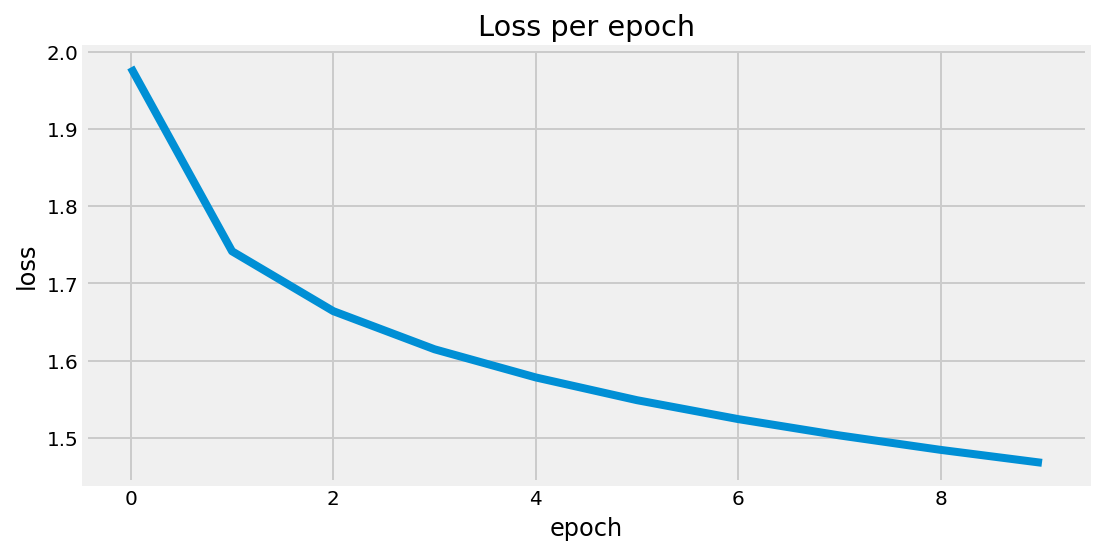

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_list)
plt.title('Loss per epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.grid(True)
plt.show()

Потери уменьшились. 

Запустим распознавание для YES_NO.

In [ ]:
lexicon_file = 'data/lexicon_yes_no.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_dict, priors_list)
records_data_dict = load_data_dict("data/yes_no/records")

run_recognizer(records_data_dict, graph, net.cpu(), beam_threshold=100)


result: no_ad89eb1e_nohash_0        ==> NO
result: yes_39a6b995_nohash_0       ==> YES
result: yes_ff63ab0b_nohash_0       ==> YES
result: yes_fc94edb0_nohash_0       ==> YES
result: no_49af4432_nohash_0        ==> NO
result: no_4394fc7c_nohash_0        ==> NO
result: no_4abb2400_nohash_0        ==> YES
result: yes_39a12648_nohash_0       ==> YES
result: no_41474817_nohash_0        ==> NO
result: yes_fe1916ba_nohash_0       ==> YES
------------------------------------------------------------
WER is: 10.00%
Total time is: 2.76 sec
------------------------------------------------------------


По этому тесту сложно судить о чём-либо, поскольку тестовый набор мал. Сеть справляется также, как и обученная без контекста.

Запустим распознавание для DIGITS.

In [ ]:
lexicon_file = 'data/lexicon_digits.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_dict, priors_list)
records_data_dict = load_data_dict("data/digits/records")

run_recognizer(records_data_dict, graph, net.cpu(), beam_threshold=50)


result: seven_fe5c4a7a_nohash_0     ==> SEVEN
result: five_f852895b_nohash_0      ==> FIVE
result: two_fce65496_nohash_0       ==> TWO
result: nine_fbe51750_nohash_0      ==> NINE
result: four_ffbb695d_nohash_0      ==> FOUR
result: six_ffbb695d_nohash_0       ==> SIX
result: one_fc2411fe_nohash_0       ==> ONE
result: zero_f92e49f3_nohash_3      ==> ZERO
result: nine_ccea893d_nohash_0      ==> NINE
result: three_feb1d305_nohash_0     ==> THREE
result: four_fce65496_nohash_0      ==> FOUR
result: seven_fd32732a_nohash_0     ==> SEVEN
result: zero_f852895b_nohash_0      ==> ZERO
result: two_fb2f3242_nohash_0       ==> TWO
result: six_ffd2ba2f_nohash_0       ==> SIX
result: five_ffd2ba2f_nohash_0      ==> FIVE
result: eight_daf230ac_nohash_0     ==> EIGHT
result: eight_da584bc0_nohash_4     ==> EIGHT
result: three_fce96bac_nohash_0     ==> THREE
result: one_ffa76c4a_nohash_0       ==> ONE
------------------------------------------------------------
WER is: 0.00%
Total time is: 22.17 sec

Здесь преимущество обученной с учётом контекста сети очевидно, качество распознавания значительно улучшилось.

### <b>Задание №2</b> (5 баллов):
Повысить качество классификации фонем за счет улучшения архитектуры нейронной сети, оптимизатора, других речевых признаков и т.п. Составить небольшой отчет на основе результатов перебора использованных способов. 

Увеличение размерности всех слоёв базовой модели до 512 привело к значительному росту WER на двух тестах, сеть переобучилась.
 
Попытаемся уменьшить количество слоёв (параметров) сети, чтобы она была менее склонной к переобучению. Также увеличим размер батча, чтобы ускорить обучение и повысить точность оценки градиента при обучении сети. Помимо этого добавим планировщик для постепенного уменьшения скорости обучения на различных эпохах.

In [ ]:
class MyNet(torch.nn.Module):
 
    def __init__(self, input_dim, output_dim):
        super(MyNet, self).__init__()
        # params:
        input_dim = input_dim       # размерность входных признаков
        n_nodes_hl1 = 256
        n_nodes_hl2 = 256
        n_nodes_hl3 = 256
        #n_nodes_hl4 = 256
        output_dim = output_dim     # количество выходных классов (фонем)
        # FC layers:
        self.fc1 = nn.Linear(input_dim, n_nodes_hl1)
        self.fc2 = nn.Linear(n_nodes_hl1, n_nodes_hl2)
        self.fc3 = nn.Linear(n_nodes_hl2, n_nodes_hl3)
        self.fc4 = nn.Linear(n_nodes_hl3, output_dim)
        #self.fc4 = nn.Linear(n_nodes_hl4, output_dim)
 
    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        #x = torch.relu(self.fc4(x))
        x = self.fc4(x)
        return (x)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
 
# load data:
data_set = CommonDataSet(data_list, device)
 
batch_size = 512
 
# training network model:
start = time.time() 
net = MyNet(input_dim=(data_list[0].shape[0] - 1),
            output_dim=len(phones_dict.keys())).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.0001)
 
#scheduler = torch.optim.lr_scheduler.OneCycleLR(
#    optimizer, max_lr=0.001, steps_per_epoch=10, epochs=10)
 
lambda1 = lambda epoch: 0.9 ** epoch
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda1)
 
loss_list = []
 
print('TRAINING IS STARTED...')
for epoch in range(10):
    running_loss = 0
    counter = 0
 
    for batch_xs, batch_ys in tqdm(data_set.next_batch(batch_size), \
                                   total=data_set.num_batches(batch_size), \
                                   desc='epoch {}'.format(epoch)):
        optimizer.zero_grad()
        output = net(batch_xs)
 
        loss = criterion(output, batch_ys)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        counter += 1
 
    scheduler.step()
        
    print('loss is: {:.4f}'.format((running_loss / counter)))
    loss_list.append(running_loss / counter)
    
end = time.time()
minutes = (end - start) // 60
seconds = np.mod((end - start), 60)
print('Time is: {} min {} sec'.format(int(minutes), int(seconds)))

TRAINING IS STARTED...



loss is: 2.1218



loss is: 1.8438



loss is: 1.7675



loss is: 1.7200



loss is: 1.6867



loss is: 1.6617



loss is: 1.6420



loss is: 1.6260



loss is: 1.6128



loss is: 1.6018
Time is: 1 min 3 sec


Благодаря большему размеру батча, сеть теперь учится в два раза быстрее.

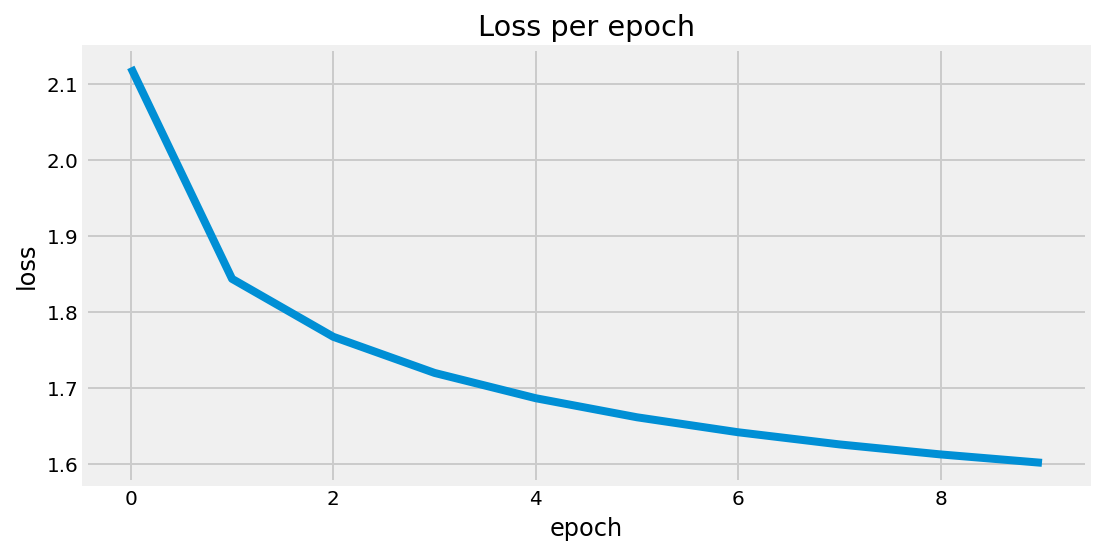

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(loss_list)
plt.title('Loss per epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.grid(True)
plt.show()

In [ ]:
lexicon_file = 'data/lexicon_yes_no.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_dict, priors_list)
records_data_dict = load_data_dict("data/yes_no/records")

run_recognizer(records_data_dict, graph, net.cpu(), beam_threshold=100)


result: no_ad89eb1e_nohash_0        ==> NO
result: yes_39a6b995_nohash_0       ==> YES
result: yes_ff63ab0b_nohash_0       ==> YES
result: yes_fc94edb0_nohash_0       ==> YES
result: no_49af4432_nohash_0        ==> NO
result: no_4394fc7c_nohash_0        ==> NO
result: no_4abb2400_nohash_0        ==> NO
result: yes_39a12648_nohash_0       ==> YES
result: no_41474817_nohash_0        ==> NO
result: yes_fe1916ba_nohash_0       ==> YES
------------------------------------------------------------
WER is: 0.00%
Total time is: 2.21 sec
------------------------------------------------------------


In [ ]:
lexicon_file = 'data/lexicon_digits.txt'
lexicon_dict = load_lexicon_dict(lexicon_file)
graph = load_graph(lexicon_dict, phones_dict, priors_list)
records_data_dict = load_data_dict("data/digits/records")
 
run_recognizer(records_data_dict, graph, net.cpu(), beam_threshold=50)


result: seven_fe5c4a7a_nohash_0     ==> SEVEN
result: five_f852895b_nohash_0      ==> FIVE
result: two_fce65496_nohash_0       ==> TWO
result: nine_fbe51750_nohash_0      ==> NINE
result: four_ffbb695d_nohash_0      ==> FOUR
result: six_ffbb695d_nohash_0       ==> SIX
result: one_fc2411fe_nohash_0       ==> ONE
result: zero_f92e49f3_nohash_3      ==> ZERO
result: nine_ccea893d_nohash_0      ==> NINE
result: three_feb1d305_nohash_0     ==> THREE
result: four_fce65496_nohash_0      ==> FOUR
result: seven_fd32732a_nohash_0     ==> SEVEN
result: zero_f852895b_nohash_0      ==> ZERO
result: two_fb2f3242_nohash_0       ==> TWO
result: six_ffd2ba2f_nohash_0       ==> SIX
result: five_ffd2ba2f_nohash_0      ==> FIVE
result: eight_daf230ac_nohash_0     ==> EIGHT
result: eight_da584bc0_nohash_4     ==> EIGHT
result: three_fce96bac_nohash_0     ==> THREE
result: one_ffa76c4a_nohash_0       ==> ONE
------------------------------------------------------------
WER is: 0.00%
Total time is: 18.08 sec

При меньшем числе параметров сеть справляется с двумя тестами не хуже первой, WER в обоих случаях составляет 0%.